# **Capstone project: Providing data-driven suggestions for HR**

## Description and deliverables

This capstone project is an opportunity for you to analyze a dataset and build predictive models that can provide insights to the Human Resources (HR) department of a large consulting firm.

Upon completion, you will have two artifacts that you will be able to present to future employers. One is a brief one-page summary of this project that you will present to external stakeholders as the data professional in Salifort Motors. The other is a complete code notebook provided here. Based on your prior coursework, select one method to complete this project: use either a regression model or a machine learning model to predict whether an employee will leave the company. The exemplar following this actiivty shows both approaches, but you only need to do one.

In your deliverables, you will include the model evaluation (and interpretation if applicable), a data visualization(s) of your choice that is directly related to the question you ask, ethical considerations, and the resources you used to troubleshoot and find answers or solutions.


# **PACE stages**


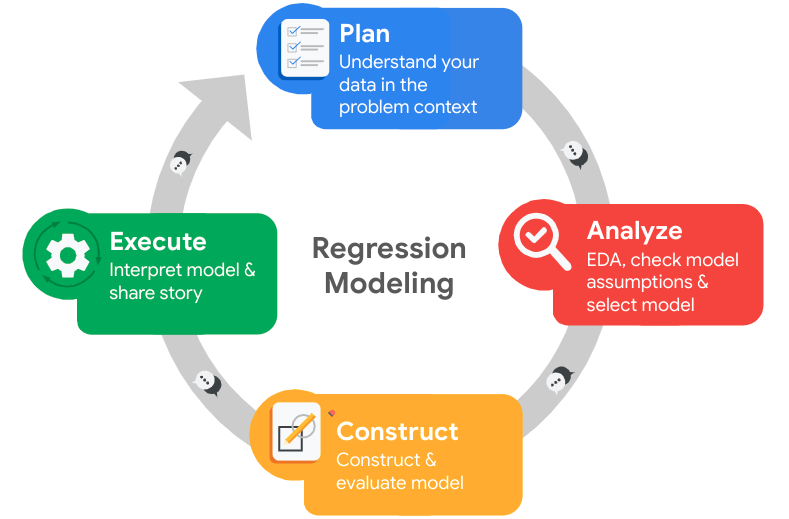

## **Pace: Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.

In this stage, consider the following:

### Understand the business scenario and problem

The HR department at Salifort Motors wants to take some initiatives to improve employee satisfaction levels at the company. They collected data from employees, but now they don’t know what to do with it. They refer to you as a data analytics professional and ask you to provide data-driven suggestions based on your understanding of the data. They have the following question: what’s likely to make the employee leave the company?

Your goals in this project are to analyze the data collected by the HR department and to build a model that predicts whether or not an employee will leave the company.

If you can predict employees likely to quit, it might be possible to identify factors that contribute to their leaving. Because it is time-consuming and expensive to find, interview, and hire new employees, increasing employee retention will be beneficial to the company.

### Familiarize yourself with the HR dataset

The dataset that you'll be using in this lab contains 15,000 rows and 10 columns for the variables listed below. 

**Note:** you don't need to download any data to complete this lab. For more information about the data, refer to its source on [Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction?select=HR_comma_sep.csv).

Variable  |Description |
-----|-----|
satisfaction_level|Employee-reported job satisfaction level [0&ndash;1]|
last_evaluation|Score of employee's last performance review [0&ndash;1]|
number_project|Number of projects employee contributes to|
average_monthly_hours|Average number of hours employee worked per month|
time_spend_company|How long the employee has been with the company (years)
Work_accident|Whether or not the employee experienced an accident while at work
left|Whether or not the employee left the company
promotion_last_5years|Whether or not the employee was promoted in the last 5 years
Department|The employee's department
salary|The employee's salary (U.S. dollars)

💭
### Reflect on these questions as you complete the plan stage.

*  Who are your stakeholders for this project?
- What are you trying to solve or accomplish?
- What are your initial observations when you explore the data?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




* **Stakeholders:** Salifort Motors' HR department and senior leadership, plus managers and the employees themselves, who are affected by any retention initiatives.
* **Goal:** Find out what is likely to make employees leave, and build a model that predicts whether an employee will leave, so HR can act on the drivers of attrition.
* **Initial observations:** 15,000 rows and 10 columns with no missing values. Some column names are misspelled or inconsistently formatted (`average_montly_hours`, `Work_accident`, `Department`). About 20% of rows are exact duplicates, and the target `left` is imbalanced (about 17% of employees left).
* **Resources:** [Kaggle dataset page](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction), [scikit-learn documentation](https://scikit-learn.org/stable/), [seaborn documentation](https://seaborn.pydata.org/), [pandas documentation](https://pandas.pydata.org/docs/).
* **Ethical considerations:** The model could be used to single out individual employees as flight risks, which could lead to unfair treatment such as being passed over for opportunities. The results should be used to improve working conditions across the company, not to penalize individuals. Employee data is personal and should be handled confidentially.

## Step 1. Imports

*   Import packages
*   Load dataset



### Import packages

In [1]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

### Load dataset

`Pandas` is used to read a dataset called **`HR_capstone_dataset.csv`.**  As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# RUN THIS CELL TO IMPORT YOUR DATA.

# Load dataset into a dataframe
df0 = pd.read_csv("HR_capstone_dataset.csv")

# Display first few rows of the dataframe
df0.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Step 2. Data Exploration (Initial EDA and data cleaning)

- Understand your variables
- Clean your dataset (missing data, redundant data, outliers)



### Gather basic information about the data

In [3]:
df0.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


### Gather descriptive statistics about the data

In [4]:
df0.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


### Rename columns

As a data cleaning step, rename the columns as needed. Standardize the column names so that they are all in `snake_case`, correct any column names that are misspelled, and make column names more concise as needed.

In [5]:
df0.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='str')

In [6]:
# Rename columns as needed
df0 = df0.rename(columns={'Work_accident': 'work_accident',
                          'average_montly_hours': 'average_monthly_hours',
                          'time_spend_company': 'tenure',
                          'Department': 'department'})

# Display all column names after the update
df0.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_monthly_hours', 'tenure', 'work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')

### Check missing values

Check for any missing values in the data.

In [7]:
df0.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_monthly_hours    0
tenure                   0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

### Check duplicates

Check for any duplicate entries in the data.

In [8]:
# Check for duplicates
print(df0.duplicated().sum())
print(round(df0.duplicated().mean() * 100, 1), '% of rows are duplicates')

3008
20.1 % of rows are duplicates


In [9]:
df0[df0.duplicated()].head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
396,0.46,0.57,2,139,3,0,1,0,sales,low
866,0.41,0.46,2,128,3,0,1,0,accounting,low
1317,0.37,0.51,2,127,3,0,1,0,sales,medium
1368,0.41,0.52,2,132,3,0,1,0,RandD,low
1461,0.42,0.53,2,142,3,0,1,0,sales,low


In [10]:
# Drop duplicates and save resulting dataframe in a new variable as needed
df1 = df0.drop_duplicates(keep='first')

# Display first few rows of new dataframe as needed
print(df1.shape)
df1.head()

(11991, 10)


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### Check outliers

Check for outliers in the data.

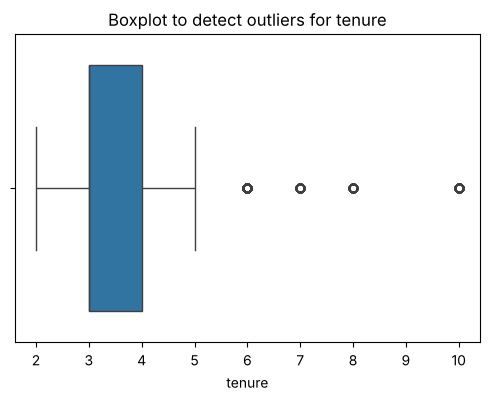

In [11]:
plt.figure(figsize=(6, 4))
plt.title('Boxplot to detect outliers for tenure', fontsize=12)
sns.boxplot(x=df1['tenure'])
plt.show()

In [12]:
# Determine the number of rows containing outliers
q1 = df1['tenure'].quantile(0.25)
q3 = df1['tenure'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr
print('Lower limit:', lower, '| Upper limit:', upper)

outliers = df1[(df1['tenure'] > upper) | (df1['tenure'] < lower)]
print('Number of rows with tenure outliers:', len(outliers))

Lower limit: 1.5 | Upper limit: 5.5
Number of rows with tenure outliers: 824


Certain types of models are more sensitive to outliers than others. When you get to the stage of building your model, consider whether to remove outliers, based on the type of model you decide to use.

# pAce: Analyze Stage
- Perform EDA (analyze relationships between variables)



💭
### Reflect on these questions as you complete the analyze stage.

- What did you observe about the relationships between variables?
- What do you observe about the distributions in the data?
- What transformations did you make with your data? Why did you chose to make those decisions?
- What are some purposes of EDA before constructing a predictive model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?




* **Relationships:** Satisfaction is much lower for employees who left (mean 0.44) than for those who stayed (0.67). Attrition is highest among employees with 2 projects (54%) and 6 to 7 projects (45% and 100%), and among employees at the 5-year mark (45%). Many leavers worked very long hours (about 250 to 300 per month) with low satisfaction. A second group of leavers worked fewer hours than average and also had low satisfaction.
* **Distributions:** Monthly hours average about 200. Tenure is right-skewed, with 824 rows flagged as outliers (more than 5.5 years). Nobody with 7 or more years of tenure left. Salary is mostly low or medium, and leave rates are lower at higher salary (high 5%, medium 15%, low 21%). Only 2% of employees were promoted in the last 5 years.
* **Transformations:** Renamed columns to snake_case and fixed typos. Dropped 3,008 duplicate rows (20% of the data), since it is very unlikely for two employees to match on every one of these variables. Encoded `salary` as an ordinal variable and dummied `department`. Kept the tenure outliers because tree-based models are robust to them.
* **Purpose of EDA:** To understand the data, find errors (duplicates, misspelled columns), spot outliers and class imbalance, and see which variables relate to the target, before choosing and building a model.
* **Resources:** [pandas documentation](https://pandas.pydata.org/docs/), [seaborn documentation](https://seaborn.pydata.org/).
* **Ethical considerations:** Dropping duplicates and keeping outliers should be documented, since they change the population being described. Department and salary could act as proxies for groups of employees, so findings should not be used to treat whole groups unfairly.

## Step 2. Data Exploration (Continue EDA)

Begin by understanding how many employees left and what percentage of all employees this figure represents.

In [13]:
# Get numbers of people who left vs. stayed
print(df1['left'].value_counts())
print()
# Get percentages of people who left vs. stayed
print(df1['left'].value_counts(normalize=True))

left
0    10000
1     1991
Name: count, dtype: int64

left
0    0.833959
1    0.166041
Name: proportion, dtype: float64


### Data visualizations

Now, examine variables that you're interested in, and create plots to visualize relationships between variables in the data.

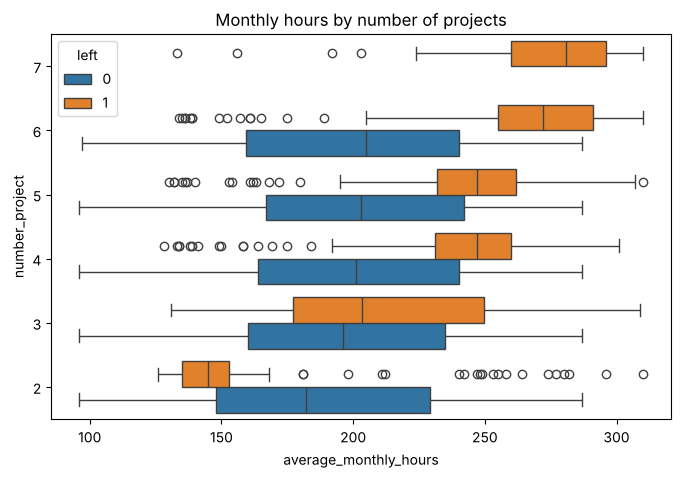

In [14]:
# Number of hours worked by number of projects, split by left
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df1, x='average_monthly_hours', y='number_project', hue='left', orient='h', ax=ax)
ax.invert_yaxis()
ax.set_title('Monthly hours by number of projects')
plt.show()

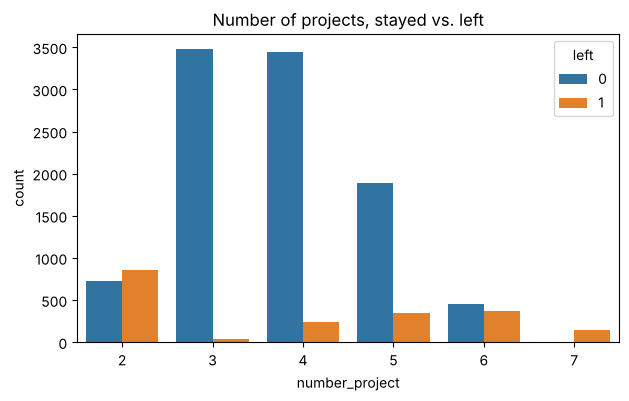

left
1    145
Name: count, dtype: int64


In [15]:
# Stayed vs. left by number of projects
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df1, x='number_project', hue='left', ax=ax)
ax.set_title('Number of projects, stayed vs. left')
plt.show()

print(df1[df1['number_project'] == 7]['left'].value_counts())

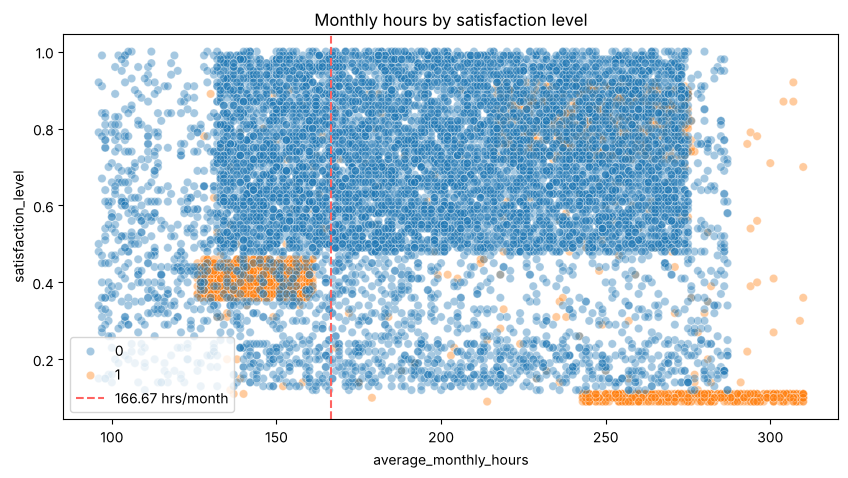

In [16]:
# Satisfaction vs. monthly hours
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df1, x='average_monthly_hours', y='satisfaction_level', hue='left', alpha=0.4)
plt.axvline(x=166.67, color='#ff6361', label='166.67 hrs/month', ls='--')
plt.legend()
plt.title('Monthly hours by satisfaction level')
plt.show()

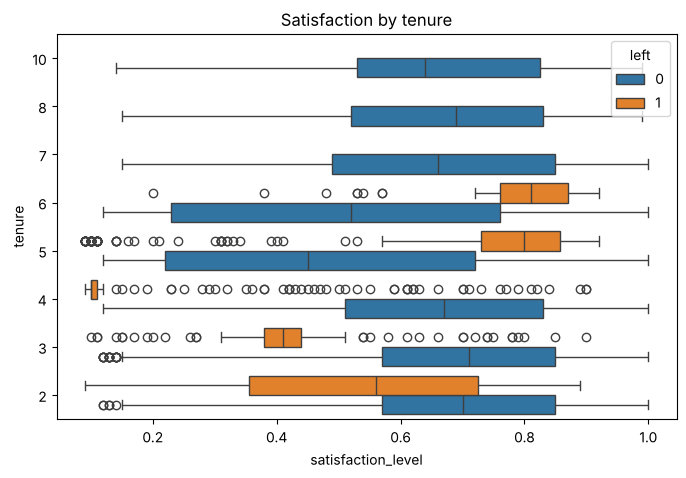

In [17]:
# Satisfaction by tenure
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df1, x='satisfaction_level', y='tenure', hue='left', orient='h', ax=ax)
ax.invert_yaxis()
ax.set_title('Satisfaction by tenure')
plt.show()

          mean  median
left                  
0     0.667365    0.69
1     0.440271    0.41


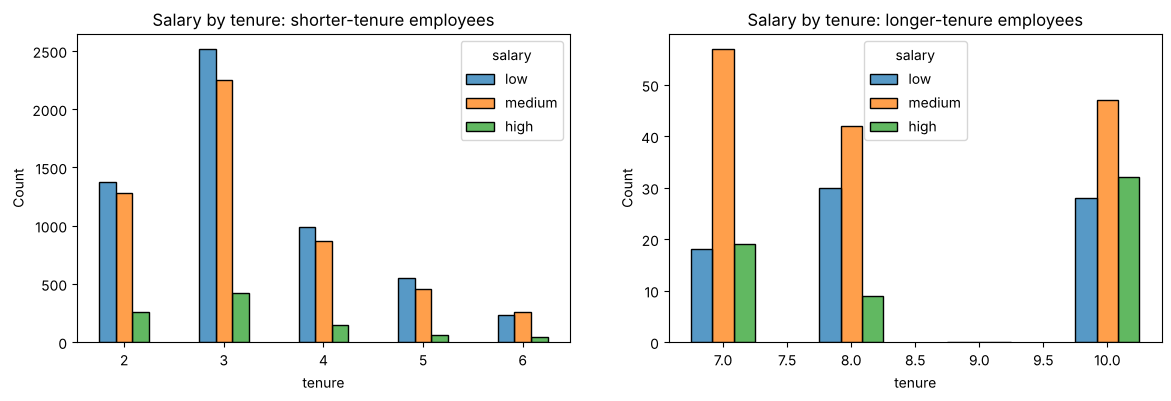

In [18]:
# Mean and median satisfaction, stayed vs. left
print(df1.groupby('left')['satisfaction_level'].agg(['mean', 'median']))

# Tenure by salary level
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
short = df1[df1['tenure'] < 7]
long = df1[df1['tenure'] > 6]
sns.histplot(data=short, x='tenure', hue='salary', discrete=1, hue_order=['low', 'medium', 'high'],
             multiple='dodge', shrink=.5, ax=ax[0])
ax[0].set_title('Salary by tenure: shorter-tenure employees')
sns.histplot(data=long, x='tenure', hue='salary', discrete=1, hue_order=['low', 'medium', 'high'],
             multiple='dodge', shrink=.5, ax=ax[1])
ax[1].set_title('Salary by tenure: longer-tenure employees')
plt.show()

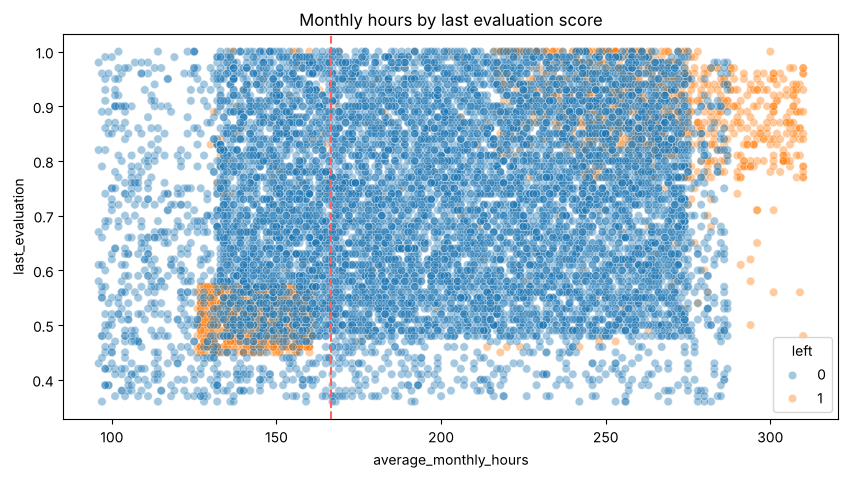

In [19]:
# Monthly hours vs. last evaluation score
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df1, x='average_monthly_hours', y='last_evaluation', hue='left', alpha=0.4)
plt.axvline(x=166.67, color='#ff6361', ls='--')
plt.title('Monthly hours by last evaluation score')
plt.show()

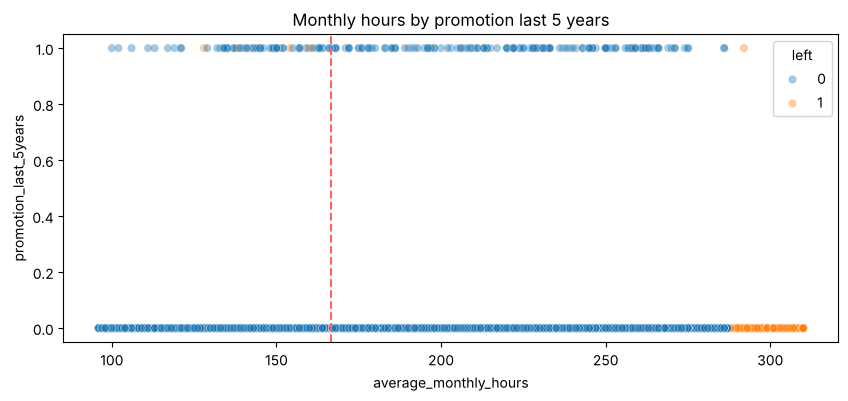

In [20]:
# Monthly hours vs. promotion in last 5 years
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df1, x='average_monthly_hours', y='promotion_last_5years', hue='left', alpha=0.4)
plt.axvline(x=166.67, color='#ff6361', ls='--')
plt.title('Monthly hours by promotion last 5 years')
plt.show()

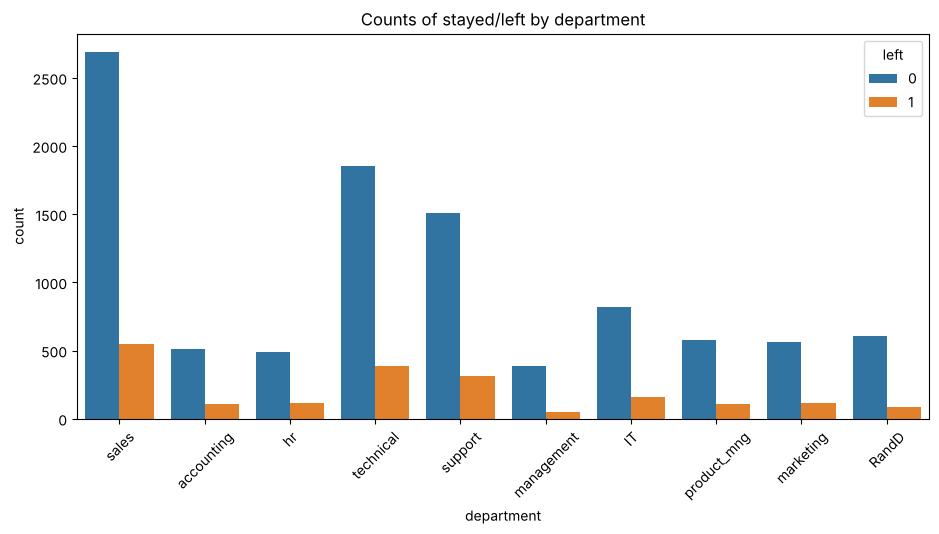

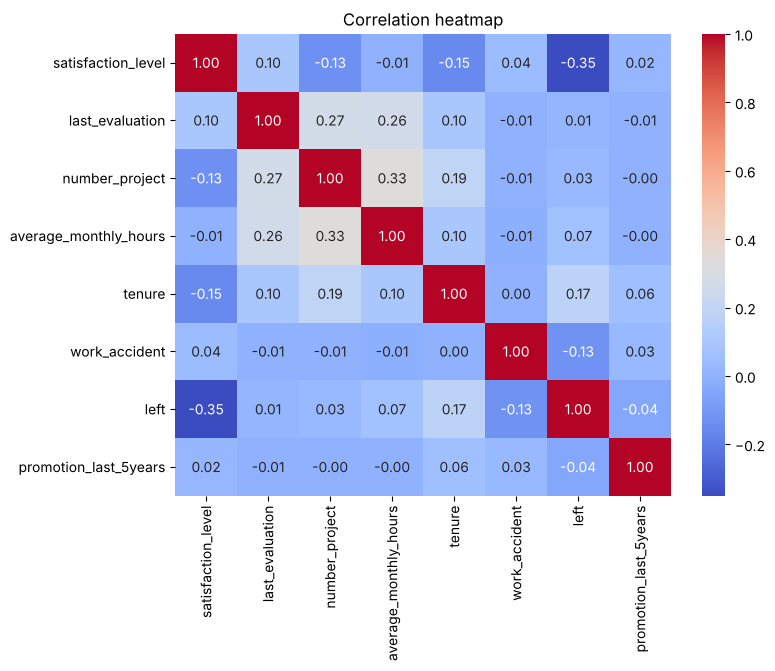

In [21]:
# Left vs. stayed by department
plt.figure(figsize=(11, 5))
sns.countplot(data=df1, x='department', hue='left')
plt.xticks(rotation=45)
plt.title('Counts of stayed/left by department')
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df1.select_dtypes('number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()

### Insights

* Employees with **2 projects** (54% left) or **6 to 7 projects** (45% for 6, 100% for 7) leave most often. Those with 3 to 4 projects are the most likely to stay (1% and 6% left).
* Many leavers **worked very long hours** (about 250 to 300 per month, well above the roughly 167 hours of a standard 40-hour week) and had very low satisfaction.
* A second group of leavers worked **fewer hours** than average and also reported low satisfaction, and they probably worked on only 2 projects.
* Attrition is highest at **5 years of tenure** (45%) and is 25% at 4 years. Nobody with 7 or more years of tenure left.
* Leavers had **lower satisfaction** than stayers (mean 0.44 vs 0.67), and satisfaction does not rise with tenure among those who left.
* Employees with **low salaries** leave more (21%) than medium (15%) and high (5%). Promotion in the last 5 years is rare (2%) and strongly associated with staying (4% left, vs 17% for those not promoted).
* **Department** shows little difference in attrition (about 12% to 19%).
* Monthly hours, number of projects and last evaluation score are positively correlated with each other, and satisfaction is negatively correlated with leaving.

# paCe: Construct Stage
- Determine which models are most appropriate
- Construct the model
- Confirm model assumptions
- Evaluate model results to determine how well your model fits the data


🔎
## Recall model assumptions

**Logistic Regression model assumptions**
- Outcome variable is categorical
- Observations are independent of each other
- No severe multicollinearity among X variables
- No extreme outliers
- Linear relationship between each X variable and the logit of the outcome variable
- Sufficiently large sample size





💭
### Reflect on these questions as you complete the constructing stage.

- Do you notice anything odd?
- Which independent variables did you choose for the model and why?
- Are each of the assumptions met?
- How well does your model fit the data?
- Can you improve it? Is there anything you would change about the model?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



* **Anything odd?** The first-round models score very high (AUC about 0.98), and `satisfaction_level` dominates. This suggests possible data leakage, since satisfaction may only be known after an employee has already decided to leave.
* **Variables:** Round 1 used all variables (satisfaction, evaluation, projects, monthly hours, tenure, work accident, promotion, salary, department). Round 2 dropped `satisfaction_level` and replaced `average_monthly_hours` with a binary `overworked` flag (more than 175 hours per month).
* **Assumptions:** Decision trees and random forests make no distributional assumptions, are not sensitive to outliers, and do not need scaling. Observations are assumed independent, which is only approximately true.
* **Fit:** The round 1 random forest reached a test AUC of 0.983, precision 0.964 and recall 0.918. The round 2 random forest, without satisfaction, still reached a test AUC of 0.968, precision 0.870 and recall 0.904.
* **Improvements:** Try gradient boosting (XGBoost), tune over a wider hyperparameter grid, and check the stability of the results with different random seeds.
* **Resources:** [scikit-learn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
* **Ethical considerations:** A model this accurate could make it tempting to act on individual predictions. It should support company-wide improvements to workload and recognition, not decisions about individuals.

## Step 3. Model Building, Step 4. Results and Evaluation
- Fit a model that predicts the outcome variable using two or more independent variables
- Check model assumptions
- Evaluate the model

### Identify the type of prediction task.

This is a **binary classification** task: predict whether an employee will leave (`left` = 1) or stay (`left` = 0).

### Identify the types of models most appropriate for this task.

Because the outcome is binary, logistic regression or tree-based machine learning models (decision tree, random forest, XGBoost) would all work. I chose a **decision tree** and a **random forest**: they do not require assumptions about linearity or multicollinearity, they are not sensitive to the outliers in `tenure`, and they handle a mix of numeric and categorical features with little preprocessing. A random forest usually generalizes better than a single tree, and a decision tree is easier to explain.

### Modeling

Add as many cells as you need to conduct the modeling process.

In [22]:
# Encode: `salary` is ordinal, `department` is dummied
df_enc = df1.copy()
df_enc['salary'] = df_enc['salary'].map({'low': 0, 'medium': 1, 'high': 2})
df_enc = pd.get_dummies(df_enc, drop_first=False)
df_enc.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,salary,department_IT,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical
0,0.38,0.53,2,157,3,0,1,0,0,False,False,False,False,False,False,False,True,False,False
1,0.80,0.86,5,262,6,0,1,0,1,False,False,False,False,False,False,False,True,False,False
2,0.11,0.88,7,272,4,0,1,0,1,False,False,False,False,False,False,False,True,False,False
3,0.72,0.87,5,223,5,0,1,0,0,False,False,False,False,False,False,False,True,False,False
4,0.37,0.52,2,159,3,0,1,0,0,False,False,False,False,False,False,False,True,False,False


In [23]:
# Helper functions to collect cross-validation and test scores
def make_results(model_name, model_object):
    '''Best CV scores (by AUC) of a fit GridSearchCV object, as a one-row df.'''
    cv = pd.DataFrame(model_object.cv_results_)
    best = cv.iloc[cv['mean_test_roc_auc'].idxmax(), :]
    return pd.DataFrame({'model': [model_name], 'precision': [best.mean_test_precision],
                         'recall': [best.mean_test_recall], 'F1': [best.mean_test_f1],
                         'accuracy': [best.mean_test_accuracy], 'AUC': [best.mean_test_roc_auc]})

def get_scores(model_name, model, X_test_data, y_test_data):
    '''Test-set scores of a fit model, as a one-row df.'''
    preds = model.predict(X_test_data)
    proba = model.predict_proba(X_test_data)[:, 1]
    return pd.DataFrame({'model': [model_name], 'precision': [precision_score(y_test_data, preds)],
                         'recall': [recall_score(y_test_data, preds)], 'F1': [f1_score(y_test_data, preds)],
                         'accuracy': [accuracy_score(y_test_data, preds)],
                         'AUC': [roc_auc_score(y_test_data, proba)]})

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

In [24]:
### Round 1: all features
y = df_enc['left']
X = df_enc.drop('left', axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(X_train.shape, X_test.shape)

(8993, 18) (2998, 18)


In [25]:
%%time
# Decision tree
tree = DecisionTreeClassifier(random_state=0)
tree_params = {'max_depth': [4, 6, 8, None], 'min_samples_leaf': [2, 5, 1], 'min_samples_split': [2, 4, 6]}
tree1 = GridSearchCV(tree, tree_params, scoring=scoring, cv=4, refit='roc_auc')
tree1.fit(X_train, y_train)
print(tree1.best_params_)
print(tree1.best_score_)

{'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 2}
0.969819392792457
CPU times: user 3.42 s, sys: 3.08 ms, total: 3.42 s
Wall time: 3.44 s


In [26]:
%%time
# Random forest
rf = RandomForestClassifier(random_state=0)
rf_params = {'max_depth': [5, None], 'max_features': [1.0], 'max_samples': [0.7],
             'min_samples_leaf': [1, 2], 'min_samples_split': [2, 4], 'n_estimators': [100]}
rf1 = GridSearchCV(rf, rf_params, scoring=scoring, cv=4, refit='roc_auc', n_jobs=-1)
rf1.fit(X_train, y_train)
print(rf1.best_params_)
print(rf1.best_score_)

{'max_depth': 5, 'max_features': 1.0, 'max_samples': 0.7, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 100}
0.9797546639713648
CPU times: user 22.1 s, sys: 7.11 ms, total: 22.1 s
Wall time: 22.3 s


In [27]:
# Cross-validation scores
results = pd.concat([make_results('decision tree cv', tree1), make_results('random forest cv', rf1)])
results

,model,precision,recall,F1,accuracy,AUC
0,decision tree cv,0.914552,0.916949,0.915707,0.971978,0.969819
0,random forest cv,0.949323,0.915614,0.932137,0.977872,0.979755


In [28]:
# Test-set scores
results = pd.concat([results,
                     get_scores('decision tree test', tree1.best_estimator_, X_test, y_test),
                     get_scores('random forest test', rf1.best_estimator_, X_test, y_test)])
results

,model,precision,recall,F1,accuracy,AUC
0,decision tree cv,0.914552,0.916949,0.915707,0.971978,0.969819
0,random forest cv,0.949323,0.915614,0.932137,0.977872,0.979755
0,decision tree test,0.936214,0.913655,0.924797,0.975317,0.978013
0,random forest test,0.964135,0.917671,0.940329,0.980654,0.982822


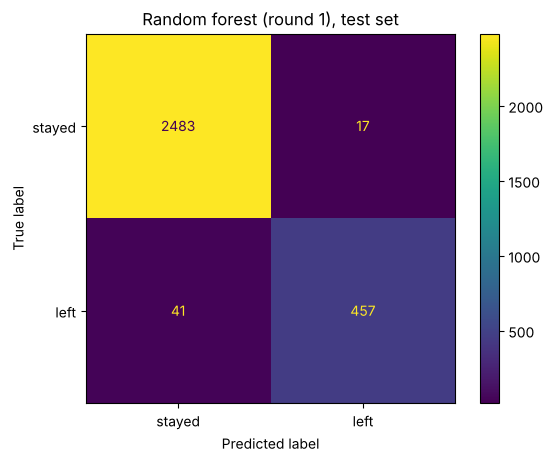

In [29]:
# Confusion matrix of the random forest on the test set
cm = confusion_matrix(y_test, rf1.best_estimator_.predict(X_test), labels=rf1.classes_)
ConfusionMatrixDisplay(cm, display_labels=['stayed', 'left']).plot(values_format='')
plt.title('Random forest (round 1), test set')
plt.show()

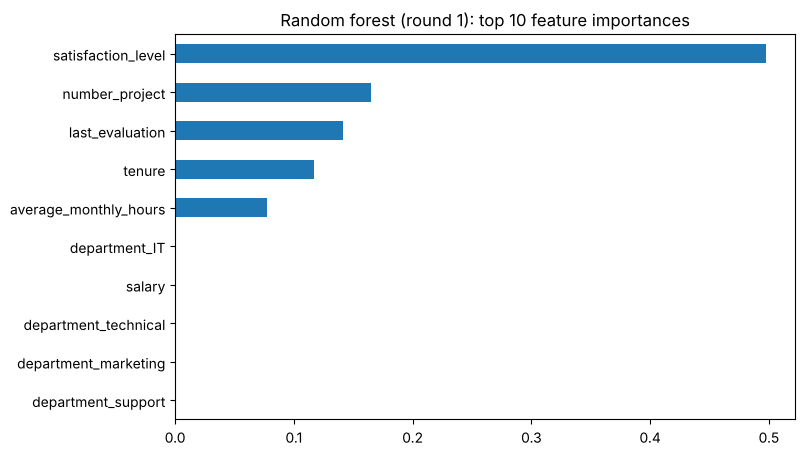

satisfaction_level       0.497216
number_project           0.165068
last_evaluation          0.141573
tenure                   0.117157
average_monthly_hours    0.077427
department_IT            0.000319
salary                   0.000264
department_technical     0.000205
department_marketing     0.000161
department_support       0.000139
dtype: float64

In [30]:
# Feature importances of the random forest
imp = pd.Series(rf1.best_estimator_.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp[::-1].plot.barh(ax=ax)
ax.set_title('Random forest (round 1): top 10 feature importances')
plt.show()
imp

In [31]:
### Round 2: drop `satisfaction_level` and add an `overworked` feature
# Satisfaction is likely to be known only after the fact and can be noisy, and it dominates the first round.
# `overworked` flags employees averaging more than 175 hours per month (roughly 50 hours per week).
df2 = df_enc.drop('satisfaction_level', axis=1)
df2['overworked'] = (df2['average_monthly_hours'] > 175).astype(int)
df2 = df2.drop('average_monthly_hours', axis=1)

y2 = df2['left']
X2 = df2.drop('left', axis=1)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.25, stratify=y2, random_state=0)

In [32]:
%%time
tree2 = GridSearchCV(DecisionTreeClassifier(random_state=0), tree_params, scoring=scoring, cv=4, refit='roc_auc')
tree2.fit(X_train2, y_train2)
print(tree2.best_params_)
print(tree2.best_score_)

{'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 6}
0.9586752505340426
CPU times: user 2.96 s, sys: 0 ns, total: 2.96 s
Wall time: 3 s


In [33]:
%%time
rf2 = GridSearchCV(RandomForestClassifier(random_state=0), rf_params, scoring=scoring, cv=4, refit='roc_auc', n_jobs=-1)
rf2.fit(X_train2, y_train2)
print(rf2.best_params_)
print(rf2.best_score_)

{'max_depth': 5, 'max_features': 1.0, 'max_samples': 0.7, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
0.9649299622944474
CPU times: user 16.1 s, sys: 23.9 ms, total: 16.1 s
Wall time: 16.2 s


In [34]:
results2 = pd.concat([make_results('decision tree2 cv', tree2), make_results('random forest2 cv', rf2),
                      get_scores('decision tree2 test', tree2.best_estimator_, X_test2, y_test2),
                      get_scores('random forest2 test', rf2.best_estimator_, X_test2, y_test2)])
results2

,model,precision,recall,F1,accuracy,AUC
0,decision tree2 cv,0.856693,0.903553,0.878882,0.958523,0.958675
0,random forest2 cv,0.862552,0.873392,0.867701,0.955854,0.964930
0,decision tree2 test,0.783877,0.917671,0.845513,0.944296,0.951595
0,random forest2 test,0.870406,0.903614,0.886700,0.961641,0.968162


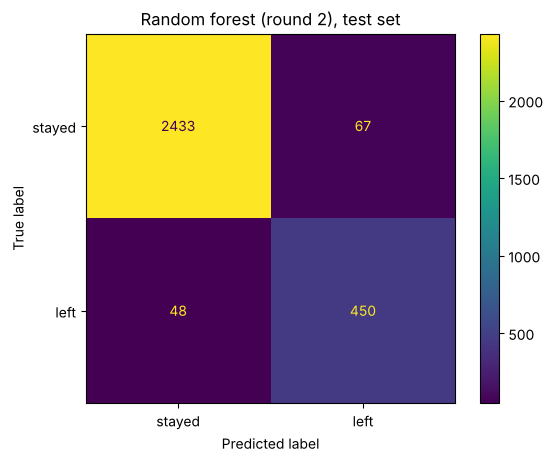

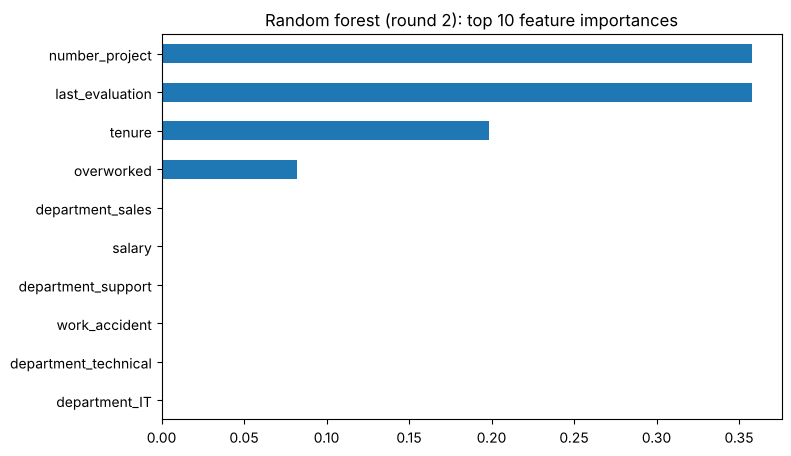

number_project          0.357874
last_evaluation         0.357563
tenure                  0.198719
overworked              0.082308
department_sales        0.000655
salary                  0.000585
department_support      0.000515
work_accident           0.000394
department_technical    0.000381
department_IT           0.000233
dtype: float64

In [35]:
# Confusion matrix and feature importances for the round 2 random forest
cm2 = confusion_matrix(y_test2, rf2.best_estimator_.predict(X_test2), labels=rf2.classes_)
ConfusionMatrixDisplay(cm2, display_labels=['stayed', 'left']).plot(values_format='')
plt.title('Random forest (round 2), test set')
plt.show()

imp2 = pd.Series(rf2.best_estimator_.feature_importances_, index=X2.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp2[::-1].plot.barh(ax=ax)
ax.set_title('Random forest (round 2): top 10 feature importances')
plt.show()
imp2

# pacE: Execute Stage
- Interpret model performance and results
- Share actionable steps with stakeholders



✏
## Recall evaluation metrics

- **AUC** is the area under the ROC curve; it's also considered the probability that the model ranks a random positive example more highly than a random negative example.
- **Precision** measures the proportion of data points predicted as True that are actually True, in other words, the proportion of positive predictions that are true positives.
- **Recall** measures the proportion of data points that are predicted as True, out of all the data points that are actually True. In other words, it measures the proportion of positives that are correctly classified.
- **Accuracy** measures the proportion of data points that are correctly classified.
- **F1-score** is an aggregation of precision and recall.






💭
### Reflect on these questions as you complete the executing stage.

- What key insights emerged from your model(s)?
- What business recommendations do you propose based on the models built?
- What potential recommendations would you make to your manager/company?
- Do you think your model could be improved? Why or why not? How?
- Given what you know about the data and the models you were using, what other questions could you address for the team?
- What resources do you find yourself using as you complete this stage? (Make sure to include the links.)
- Do you have any ethical considerations in this stage?



* **Key insights:** Attrition is driven mainly by workload and satisfaction. Employees with 2 projects (likely underused or on their way out) or with 6 to 7 projects (overloaded, with every 7-project employee leaving) leave most often. Employees who work very long hours report low satisfaction. Attrition peaks at 4 to 5 years of tenure, and nobody with more than 6 years of tenure left. Leave rates are lower for employees who were promoted and for those with higher salaries.
* **Recommendations:** Cap the number of projects per employee, and clarify or reward overtime. Look into why employees at 4 to 5 years of tenure are dissatisfied, and consider promotion and career path conversations at that point. Do not reward employees who work long hours without recognition or support. Hold company-wide discussions about work culture, and consider whether hours beyond a typical week of about 50 hours are expected.
* **Model improvement:** The model is already accurate, and it could be improved with more recent data, more features such as manager, role and commute, and boosted models. Because the first round likely leaks information through satisfaction, the round 2 model without it is the more realistic one.
* **Other questions:** How do hours, projects and satisfaction change over time for the same employee? Which employees who were rated highly and left would be most costly to lose? Do the patterns differ by department?
* **Resources:** [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).
* **Ethical considerations:** Use predictions to improve working conditions, not to penalize or monitor individuals. Share results with employees' privacy in mind and avoid acting on predictions about identifiable people.

## Step 4. Results and Evaluation
- Interpret model
- Evaluate model performance using metrics
- Prepare results, visualizations, and actionable steps to share with stakeholders




### Summary of model results

**Round 1 (all features), test set**

| Model | Precision | Recall | F1 | Accuracy | AUC |
|---|---|---|---|---|---|
| Decision tree | 0.936 | 0.914 | 0.925 | 0.975 | 0.978 |
| Random forest | 0.964 | 0.918 | 0.940 | 0.981 | 0.983 |

**Round 2 (no `satisfaction_level`, with `overworked`), test set**

| Model | Precision | Recall | F1 | Accuracy | AUC |
|---|---|---|---|---|---|
| Decision tree | 0.784 | 0.918 | 0.846 | 0.944 | 0.952 |
| Random forest | 0.870 | 0.904 | 0.887 | 0.962 | 0.968 |

The random forest is the better model in both rounds. In round 1, the most important features are `satisfaction_level`, `number_project`, `last_evaluation`, `tenure` and `average_monthly_hours`. In round 2, they are `number_project`, `last_evaluation`, `tenure` and `overworked`. Scores drop slightly without satisfaction, but the model remains strong.

### Conclusion, Recommendations, Next Steps

**Conclusion:** The data supports the view that employees at Salifort Motors leave because of **overwork and poor job satisfaction**, and a significant group also leave when they appear underused. The random forest predicts attrition well (test AUC of 0.983 with all features, and 0.968 without satisfaction).

**Recommendations to stakeholders:**
* Cap the number of projects an employee can take on at once (for example, 5).
* Investigate why employees at 4 to 5 years of tenure are leaving, and consider promoting them or giving clearer career paths.
* Either reward employees for working longer hours, or stop expecting them to.
* Make overtime expectations and time-off policies clear to all employees.
* Hold company-wide and team-level discussions to understand and address the work culture.
* Recognize and reward employees who perform well without working extreme hours, since evaluation scores are positively correlated with hours worked.

**Next steps:**
* The very high scores suggest possible data leakage, so confirm how `satisfaction_level` is collected and when.
* Try other models, such as gradient boosting, and tune further.
* Collect more detailed data (for example, manager, role, tenure history, and exit surveys) to look at the causes in more detail.
* Use predictions to support employee-wide improvements, and avoid using them to penalize individuals.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.